# Complete NLP/ML Pipeline for Legal Contract Clause Analysis
This notebook contains the complete NLP + Machine Learning pipeline for the **AI-Based Legal Contract Clause Detection and Risk Analysis** project using the `CUAD_combined.csv` dataset.

We will focus on:
1. Transforming the dataset into a snippet-level multi-label format.
2. Preventing data leakage via a Contract-Level Train/Test Split.
3. Building robust NLP preprocessing for legal text.
4. Training and evaluating classical Machine Learning Baselines (Logistic Regression, Linear SVM, Naive Bayes).
5. Interpreting features and establishing a Risk Scoring Layer.


In [1]:
import pandas as pd
import numpy as np
import ast
import re
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
from nltk.corpus import stopwords
import warnings
import joblib

warnings.filterwarnings('ignore')

# Download required NLTK resources
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)


True

## 1. Dataset Loading & Structural Understanding
We load the dataset and identify the metadata, text columns, and label columns.
*Why we do this:* To understand the input format before performing any data transformation.


In [2]:
df = pd.read_csv('CUAD_combined.csv')
print(f"Dataset Shape: {df.shape}")

# Identify clause and answer columns
all_cols = list(df.columns)
clause_cols = [c for c in all_cols if c + '_answer' in all_cols]
answer_cols = [c + '_answer' for c in clause_cols]

print(f"Number of clause categories: {len(clause_cols)}")


Dataset Shape: (510, 84)
Number of clause categories: 41


## 2. Multi-label Snippet Data Transformation
Because a single contract contains multiple clauses and a single text snippet could conceptually belong to multiple clause categories, we flatten the dataset into a snippet-level multi-label format.
*Why we do this:* It allows us to naturally generate positive and negative examples. A snippet extracted from the `non_compete` column is a positive example for `non_compete` and a negative example for other clauses from the same contract.


In [3]:
snippets = []
for idx, row in df.iterrows():
    doc_id = idx # Using index as document ID
    for c in clause_cols:
        val = row[c]
        if isinstance(val, str) and val not in ['[]', '']:
            try:
                # The text is stringified lists
                texts = ast.literal_eval(val)
                for t in texts:
                    snippets.append({
                        'document_id': doc_id,
                        'source_file': row['source_file'],
                        'clause_type': c,
                        'text': t
                    })
            except:
                pass

df_snippets = pd.DataFrame(snippets)
print(f"Total extracted non-empty snippets: {len(df_snippets)}")

# Group by document_id and text to create multi-label targets
df_multi = df_snippets.groupby(['document_id', 'source_file', 'text'])['clause_type'].apply(lambda x: list(set(x))).reset_index()

# Create binary columns for each clause type
for c in clause_cols:
    df_multi[c] = df_multi['clause_type'].apply(lambda x: 1 if c in x else 0)

print(f"Unique snippet shape: {df_multi.shape}")
df_multi.head(3)


Total extracted non-empty snippets: 13101


Unique snippet shape: (11850, 45)


,document_id,source_file,text,clause_type,document_name,parties,agreement_date,effective_date,expiration_date,renewal_term,...,source_code_escrow,post_termination_services,audit_rights,uncapped_liability,cap_on_liability,liquidated_damages,warranty_duration,insurance,covenant_not_to_sue,third_party_beneficiary
0,0,CUAD_v1/master_clauses.csv,8th day of May 2014,[agreement_date],0,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,CUAD_v1/master_clauses.csv,BIRCH FIRST GLOBAL INVESTMENTS INC.,[parties],0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,CUAD_v1/master_clauses.csv,COMPANY'S SOLE AND EXCLUSIVE LIABILITY FOR THE...,[cap_on_liability],0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0


## 3. Exploratory Data Analysis (EDA)
Let's look at the class distribution to understand if we have class imbalance.
*Why we do this:* Imbalanced data severely affects model training and requires specific evaluation metrics (like Macro-F1 instead of Accuracy) and techniques like `class_weight`.


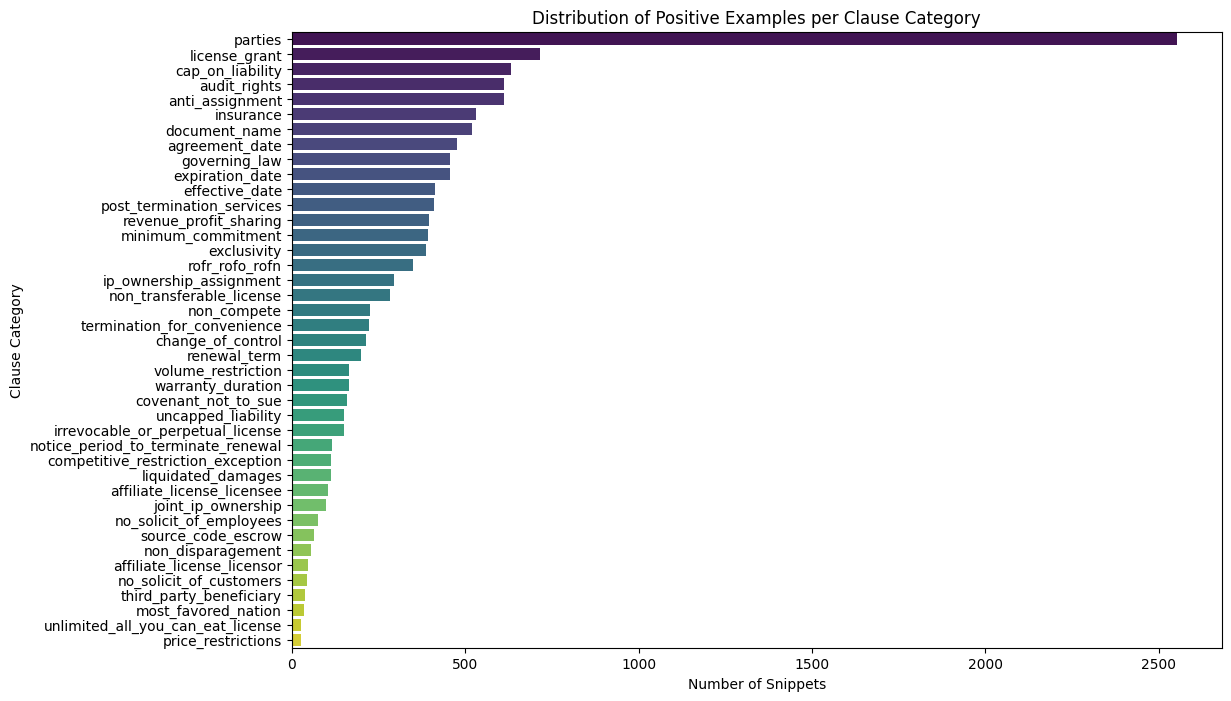

Top 5 most frequent clauses:
parties             2554
license_grant        716
cap_on_liability     632
audit_rights         613
anti_assignment      612
dtype: int64

Top 5 least frequent clauses:
no_solicit_of_customers              45
third_party_beneficiary              39
most_favored_nation                  36
unlimited_all_you_can_eat_license    27
price_restrictions                   26
dtype: int64


In [4]:
# Class Distribution
class_counts = df_multi[clause_cols].sum().sort_values(ascending=False)

plt.figure(figsize=(12, 8))
sns.barplot(x=class_counts.values, y=class_counts.index, palette="viridis")
plt.title("Distribution of Positive Examples per Clause Category")
plt.xlabel("Number of Snippets")
plt.ylabel("Clause Category")
plt.show()

print("Top 5 most frequent clauses:")
print(class_counts.head(5))
print("\nTop 5 least frequent clauses:")
print(class_counts.tail(5))


## 4. Contract-Level Train/Test Split (Preventing Data Leakage)
We split the data by `document_id`.
*Why we do this:* If we split purely randomly, snippets from the same contract would end up in both the training and testing sets, leaking information about formatting and specific entities.


In [5]:
from sklearn.model_selection import GroupShuffleSplit

gss = GroupShuffleSplit(n_splits=1, train_size=0.8, random_state=42)
train_idx, test_idx = next(gss.split(df_multi, groups=df_multi['document_id']))

df_train = df_multi.iloc[train_idx]
df_test = df_multi.iloc[test_idx]

print(f"Training snippets: {len(df_train)} (Contracts: {df_train['document_id'].nunique()})")
print(f"Testing snippets: {len(df_test)} (Contracts: {df_test['document_id'].nunique()})")

X_train = df_train['text']
y_train = df_train[clause_cols].values
X_test = df_test['text']
y_test = df_test[clause_cols].values


Training snippets: 9539 (Contracts: 408)
Testing snippets: 2311 (Contracts: 102)


## 5. NLP Preprocessing
We define a robust preprocessing function.
*Why we do this:* Legal text contains formatting noise (newlines, weird spaces), but we MUST KEEP critical legal stop words like 'shall', 'may', 'except', 'unless', which dictate obligation and condition.


In [6]:
def preprocess_legal_text(text):
    # Lowercase
    text = text.lower()
    # Remove unicode formatting and strange whitespace
    text = re.sub(r'\\s+', ' ', text)
    # Basic tokenization to remove non-alphanumeric noise, but keep structure
    text = re.sub(r'[^a-zA-Z0-9\\s.,;]', '', text)
    
    # We do NOT remove standard stopwords aggressively because "shall not" is very different from "shall"
    return text.strip()

X_train_clean = X_train.apply(preprocess_legal_text)
X_test_clean = X_test.apply(preprocess_legal_text)


## 6. TF-IDF & Classical ML Baselines
We train Logistic Regression, Linear SVM, and Multinomial Naive Bayes using TF-IDF (unigrams and bigrams).
Since this is multi-label, we wrap them in a `OneVsRestClassifier`. We use `class_weight='balanced'` to handle the severe class imbalance.
*Why we do this:* To establish strong baselines before jumping into complex deep learning models. TF-IDF with linear models often performs exceptionally well on text classification while remaining interpretable.


In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.multiclass import OneVsRestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import f1_score, precision_score, recall_score, classification_report
import time

vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=2, max_df=0.95)
X_train_vec = vectorizer.fit_transform(X_train_clean)
X_test_vec = vectorizer.transform(X_test_clean)

models = {
    'Logistic Regression': OneVsRestClassifier(LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)),
    'Linear SVM': OneVsRestClassifier(LinearSVC(class_weight='balanced', random_state=42)),
    'Naive Bayes': OneVsRestClassifier(MultinomialNB()) # NB doesn't support class_weight natively
}

results = []

for name, model in models.items():
    start = time.time()
    model.fit(X_train_vec, y_train)
    preds = model.predict(X_test_vec)
    
    macro_f1 = f1_score(y_test, preds, average='macro')
    micro_f1 = f1_score(y_test, preds, average='micro')
    precision = precision_score(y_test, preds, average='macro', zero_division=0)
    recall = recall_score(y_test, preds, average='macro', zero_division=0)
    
    results.append({
        'Model': name,
        'Precision (Macro)': precision,
        'Recall (Macro)': recall,
        'F1 (Macro)': macro_f1,
        'F1 (Micro)': micro_f1,
        'Time (s)': time.time() - start
    })
    
results_df = pd.DataFrame(results)
display(results_df)


,Model,Precision (Macro),Recall (Macro),F1 (Macro),F1 (Micro),Time (s)
0,Logistic Regression,0.218710,0.338674,0.231963,0.259670,0.656164
1,Linear SVM,0.189754,0.502625,0.206170,0.123489,1.653439
2,Naive Bayes,0.213767,0.036057,0.056997,0.218739,0.063553


## 7. Model Evaluation
Let's visualize the results. We use Macro-F1 because it treats all clauses equally, penalizing models that fail on rare clauses.
*Why we do this:* Accuracy is highly misleading when rare clauses make up < 1% of the dataset.


In [8]:
best_model_name = results_df.sort_values(by='F1 (Macro)', ascending=False).iloc[0]['Model']
print(f"Best model based on Macro-F1 is: {best_model_name}")

best_model = models[best_model_name]

# Show detailed classification report for the best model
preds = best_model.predict(X_test_vec)
print(classification_report(y_test, preds, target_names=clause_cols, zero_division=0))


Best model based on Macro-F1 is: Logistic Regression
                                    precision    recall  f1-score   support

                     document_name       1.00      0.55      0.71       104
                           parties       0.93      0.39      0.55       519
                    agreement_date       0.68      0.84      0.75        95
                    effective_date       0.45      0.71      0.55        80
                   expiration_date       0.13      0.20      0.16        93
                      renewal_term       0.11      0.16      0.13        45
notice_period_to_terminate_renewal       0.19      0.22      0.21        32
                     governing_law       0.86      0.43      0.57        89
               most_favored_nation       0.02      0.14      0.03         7
 competitive_restriction_exception       0.08      0.41      0.13        22
                       non_compete       0.13      0.38      0.20        37
                       exclusivity

## 8. Feature Interpretation
For legal AI, interpretability is crucial. Let's see which words the Logistic Regression or SVM model learned to associate with a specific clause.
*Why we do this:* To ensure the model is learning actual legal concepts (e.g. "terminate" for termination clauses) rather than spurious correlations.


In [9]:
if best_model_name in ['Logistic Regression', 'Linear SVM']:
    feature_names = vectorizer.get_feature_names_out()
    
    # Pick a couple of interesting clauses
    sample_clauses = ['non_compete', 'termination_for_convenience']
    
    for clause in sample_clauses:
        idx = clause_cols.index(clause)
        coefs = best_model.estimators_[idx].coef_[0]
        top_positive_idx = np.argsort(coefs)[-10:]
        top_features = [feature_names[i] for i in top_positive_idx]
        
        print(f"--- Top features for {clause} ---")
        print(", ".join(top_features))
        print()


--- Top features for non_compete ---
develop, partner, locationfranchiselocation, endorsersdutynottocompetewiththebusinessofmusclepharmshallcontinueforaperiodofoneyearfollowingtheexpirationorterminationofthisagreement, thefranchiseagreementcontainsacovenantnottocompetewhichextendsbeyondtheterminationofthefranchise, discussions, asspecifiedinexhibite, directlyorindirectly, forthepurposesofthisagreement, promote

--- Top features for termination_for_convenience ---
upontheoccurrenceofanyofthefollowing, 9and10hereof, followingtheinitialterm, initssoleandabsolutediscretion, eitherpartymayterminatethisagreementatanytimeonpriorwrittennoticetotheother, thisagreementmayalsobeterminatedbyeitherpartyuponninety90dayswrittennotice, withorwithoutcause, atanytimewithoutcause, eitherpartymayterminatethisagreementatanytimewith30dayswrittennotice, withoutcause



## 9. Inference & Risk Scoring Layer
We build a unified `analyze_contract` function. It takes raw text, segments it, predicts clauses, and computes a heuristic risk score.
*Why we do this:* This matches the exact output format needed for later Django backend integration. The risk score is a *project-defined heuristic*, NOT absolute legal truth.


In [10]:
# Heuristic risk weights for demonstration
risk_weights = {
    'non_compete': 2,
    'exclusivity': 2,
    'uncapped_liability': 3,
    'irrevocable_or_perpetual_license': 3,
    'termination_for_convenience': 1,
    'audit_rights': 1
}

def analyze_contract(text, model, vectorizer, clause_cols):
    # 1. Segment text (Very naive chunking by double newline or sentences for demonstration)
    chunks = [c for c in text.split('\n\n') if len(c.strip()) > 50]
    if not chunks:
        chunks = [text]
        
    # 2. Preprocess
    clean_chunks = [preprocess_legal_text(c) for c in chunks]
    vec_chunks = vectorizer.transform(clean_chunks)
    
    # 3. Predict
    preds = model.predict(vec_chunks)
    
    detected_clauses = set()
    extracted_clauses = []
    total_risk = 0
    
    for i, chunk_preds in enumerate(preds):
        for j, is_present in enumerate(chunk_preds):
            if is_present:
                clause = clause_cols[j]
                detected_clauses.add(clause)
                extracted_clauses.append({
                    'Clause Type': clause,
                    'Extracted Text': chunks[i]
                })
                
    for dc in detected_clauses:
        total_risk += risk_weights.get(dc, 0)
        
    risk_level = "Low"
    if total_risk > 3: risk_level = "Medium"
    if total_risk > 6: risk_level = "High"
    
    return {
        "detected_clauses": list(detected_clauses),
        "extracted_clauses": extracted_clauses,
        "risk_score": total_risk,
        "risk_level": risk_level,
        "summary": f"Detected {len(detected_clauses)} unique clauses from {len(chunks)} text chunks."
    }

# Test the inference function on a real snippet from the test set
sample_text = X_test.iloc[0] + "\n\n" + X_test.iloc[1] if len(X_test) > 1 else X_test.iloc[0]
print("Running Sample Inference...\n")
result = analyze_contract(sample_text, best_model, vectorizer, clause_cols)

print(f"Detected Clauses: {result['detected_clauses']}")
print(f"Risk Score: {result['risk_score']} ({result['risk_level']})")
print(f"Summary: {result['summary']}")
print("\nFirst Extracted Clause:")
if result['extracted_clauses']:
    print(result['extracted_clauses'][0])


Running Sample Inference...

Detected Clauses: ['warranty_duration']
Risk Score: 0 (Low)
Summary: Detected 1 unique clauses from 1 text chunks.

First Extracted Clause:
{'Clause Type': 'warranty_duration', 'Extracted Text': '8th day of May 2014\n\nBIRCH FIRST GLOBAL INVESTMENTS INC.'}


## 10. Model Saving
Save the pipeline components using `joblib` so the Django backend can load them easily.


In [11]:
import os

os.makedirs('models', exist_ok=True)
joblib.dump(vectorizer, 'models/tfidf_vectorizer.joblib')
joblib.dump(best_model, 'models/best_model.joblib')
joblib.dump(clause_cols, 'models/clause_categories.joblib')

print("Models saved successfully to models/ directory.")


Models saved successfully to models/ directory.
